# When Should You Post to Hacker News? Probably Whenever.

**Dataset:** 20,100 Hacker News submissions, from a Kaggle dump covering roughly twelve months to September 2016.

---

## The two claims

This project usually ends with two pieces of advice:

1. **Ask HN posts get more comments than Show HN posts.**
2. **Post at 15:00 US Eastern**, which averages 38.6 comments against a typical hour's 10 to 15.

The first is true and much smaller than it sounds. The second does not survive a significance test: **shuffling the comment counts at random produces a best-hour average that high 13% of the time.**

There is also a problem with the dataset itself that caps what any conclusion from it can mean, and it is visible in one line of summary statistics.

Written with the standard library plus NumPy and Matplotlib, since this course does not install pandas.

## 1. Loading

In [1]:
%matplotlib inline

import csv
import random
import statistics as stats
import datetime as dt
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

with open("hacker_news.csv") as f:
    rows = list(csv.reader(f))

header, posts = rows[0], rows[1:]
print("columns:", header)
print("posts:  ", len(posts))
print("example:", posts[0])

ID, TITLE, URL, POINTS, COMMENTS, AUTHOR, CREATED = range(7)

comments = [int(p[COMMENTS]) for p in posts]
points = [int(p[POINTS]) for p in posts]

columns: ['id', 'title', 'url', 'num_points', 'num_comments', 'author', 'created_at']
posts:   20100
example: ['12224879', 'Interactive Dynamic Video', 'http://www.interactivedynamicvideo.com/', '386', '52', 'ne0phyte', '8/4/2016 11:52']


## 2. The line that limits everything else

Before any analysis, the range of the two outcome variables.

In [2]:
print("num_comments: min %d, max %d" % (min(comments), max(comments)))
print("num_points:   min %d, max %d" % (min(points), max(points)))
print()
print("posts with zero comments: %d" % sum(1 for c in comments if c == 0))
print("posts with zero points:   %d" % sum(1 for p in points if p == 0))

num_comments: min 1, max 1733
num_points:   min 1, max 2553

posts with zero comments: 0
posts with zero points:   0


**The minimum number of comments is 1, and the minimum number of points is 1. Not a single post in 20,100 received zero of either.**

That does not happen naturally. The great majority of Hacker News submissions sink without a comment or an upvote; the full Kaggle dump this is drawn from contains around 300,000 posts, and this file holds 20,100 of them. The dataset has been filtered to submissions that got some traction.

So every question of the form "what makes a post succeed?" is being asked of a sample where **failure has already been removed**. The honest framing of any result below is conditional: given that a post got at least one comment and one point, what else is true of it? That is a much weaker question than the one the project sets, and no amount of careful analysis downstream can recover the missing posts.

This limitation is stated once here and applies to everything that follows.

## 3. How skewed is the outcome?

In [3]:
def describe(name, values):
    s = sorted(values)
    n = len(s)
    print("%-10s n=%5d  mean %7.2f  median %5.1f  p90 %6.0f  p99 %6.0f  max %6d" % (
          name, n, stats.mean(s), stats.median(s), s[int(0.90 * n)], s[int(0.99 * n)], s[-1]))

describe("comments", comments)
describe("points", points)
print()

top_1pct = sorted(comments)[int(0.99 * len(comments)):]
print("the top 1%% of posts by comments (%d posts) hold %.1f%% of all comments" % (
      len(top_1pct), 100 * sum(top_1pct) / sum(comments)))
print()
print("mean is %.1fx the median. On a distribution this skewed, a mean is a" %
      (stats.mean(comments) / stats.median(comments)))
print("statement about the handful of posts that went viral, not about a typical post.")

comments   n=20100  mean   24.80  median   3.0  p90     74  p99    261  max   1733
points     n=20100  mean   50.30  median   9.0  p90    141  p99    485  max   2553

the top 1% of posts by comments (201 posts) hold 15.5% of all comments

mean is 8.3x the median. On a distribution this skewed, a mean is a
statement about the handful of posts that went viral, not about a typical post.


## 4. Claim one: do Ask HN posts get more comments?

In [4]:
def starts_with(post, prefix):
    return post[TITLE].lower().startswith(prefix)

ask = [p for p in posts if starts_with(p, "ask hn")]
show = [p for p in posts if starts_with(p, "show hn")]
other = [p for p in posts if not starts_with(p, "ask hn") and not starts_with(p, "show hn")]

print("%-8s %7s %11s %10s %11s %10s" % (
      "group", "n", "mean com", "med com", "mean pts", "med pts"))
for name, group in [("ask", ask), ("show", show), ("other", other)]:
    c = [int(p[COMMENTS]) for p in group]
    pt = [int(p[POINTS]) for p in group]
    print("%-8s %7d %11.2f %10.1f %11.2f %10.1f" % (
          name, len(group), stats.mean(c), stats.median(c), stats.mean(pt), stats.median(pt)))

group          n    mean com    med com    mean pts    med pts
ask         1744       14.04        4.0       15.06        4.0
show        1162       10.32        3.0       27.56        6.0
other      17194       26.87        3.0       55.41       11.0


In [5]:
def permutation_test(a, b, statistic, n_shuffles=5000, seed=7):
    """Two-sided test: how often does reshuffling the group labels produce a
    difference at least as large as the one observed?"""
    observed = statistic(a) - statistic(b)
    pooled = list(a) + list(b)
    rng = random.Random(seed)
    split = len(a)
    extreme = 0
    for _ in range(n_shuffles):
        rng.shuffle(pooled)
        if abs(statistic(pooled[:split]) - statistic(pooled[split:])) >= abs(observed):
            extreme += 1
    return observed, extreme / n_shuffles

ask_comments = [int(p[COMMENTS]) for p in ask]
show_comments = [int(p[COMMENTS]) for p in show]

diff, p_value = permutation_test(ask_comments, show_comments, stats.median)
print("ASK vs SHOW, median comments")
print("  ask %.1f, show %.1f, difference %.1f" % (
      stats.median(ask_comments), stats.median(show_comments), diff))
print("  permutation p = %.4f" % p_value)
print()
print("Real, but the effect is one comment at the median.")
print()
print("And it reverses on points:")
print("  ask median points:   %.1f" % stats.median([int(p[POINTS]) for p in ask]))
print("  show median points:  %.1f" % stats.median([int(p[POINTS]) for p in show]))
print("  other median points: %.1f" % stats.median([int(p[POINTS]) for p in other]))

ASK vs SHOW, median comments
  ask 4.0, show 3.0, difference 1.0
  permutation p = 0.0032

Real, but the effect is one comment at the median.

And it reverses on points:
  ask median points:   4.0
  show median points:  6.0
  other median points: 11.0


**The claim holds, and it is worth one comment.**

Ask HN posts have a median of 4 comments against Show HN's 3. The permutation test puts that at p = 0.0032, so it is unlikely to be chance, but the practical size of the effect is a single comment.

**On points the ranking inverts.** Show HN posts have a median of 6 points against Ask HN's 4, and ordinary link posts beat both at 11. The two formats are not better and worse; they attract different things. Asking a question gets you replies, showing your work gets you upvotes, and posting an interesting link gets you considerably more upvotes than either.

Note how differently the means read: ordinary posts average 26.87 comments against Ask HN's 14.04, which would flip the headline entirely. That gap between mean and median is the subject of the next section.

## 5. Claim two: is 15:00 the best hour to post?

The standard analysis groups Ask HN posts by posting hour and takes the mean comments per hour.

In [6]:
by_hour = defaultdict(list)
for p in ask:
    created = dt.datetime.strptime(p[CREATED], "%m/%d/%Y %H:%M")
    by_hour[created.hour].append(int(p[COMMENTS]))

print("ASK HN comments by posting hour (US/Eastern)")
print("%5s %6s %9s %9s %8s %13s" % ("hour", "n", "mean", "median", "max", "biggest post"))
hour_rows = []
for h in sorted(by_hour):
    v = by_hour[h]
    share = 100 * max(v) / sum(v)
    hour_rows.append({"hour": h, "n": len(v), "mean": stats.mean(v),
                      "median": stats.median(v), "max": max(v), "share": share})
    print("%5d %6d %9.2f %9.1f %8d %12.1f%%" %
          (h, len(v), stats.mean(v), stats.median(v), max(v), share))

best_mean = max(hour_rows, key=lambda r: r["mean"])
best_median = max(hour_rows, key=lambda r: r["median"])
print()
print("best hour by MEAN:   %02d:00  (%.2f comments, n=%d)" %
      (best_mean["hour"], best_mean["mean"], best_mean["n"]))
print("best hour by MEDIAN: %02d:00  (%.1f comments, n=%d)" %
      (best_median["hour"], best_median["median"], best_median["n"]))

ASK HN comments by posting hour (US/Eastern)
 hour      n      mean    median      max  biggest post
    0     55      8.13       3.0       61         13.6%
    1     60     11.38       4.0       69         10.1%
    2     58     23.81       5.0      868         62.9%
    3     54      7.80       3.5       44         10.5%
    4     47      7.17       3.0       62         18.4%
    5     46     10.09       3.0      117         25.2%
    6     44      9.02       2.5       73         18.4%
    7     34      7.85       5.5       53         19.9%
    8     48     10.25       3.0      130         26.4%
    9     45      5.58       2.0       60         23.9%
   10     59     13.44       4.0      109         13.7%
   11     58     11.05       3.0      266         41.5%
   12     73      9.41       4.0       73         10.6%
   13     85     14.74       5.0      231         18.4%
   14    107     13.23       3.0      190         13.4%
   15    116     38.59       3.0      947         21.2%
   

**The two statistics give completely different answers.**

By mean, 15:00 wins at 38.59. By median, 15:00 scores **3.0**, which ties it with 00:00, 04:00, 05:00, 08:00, 11:00, 14:00, 19:00 and 21:00. The median-best hour is 07:00, on the smallest sample in the table (n=34).

The "biggest post" column shows why. At 15:00 a single 947-comment post supplies 21.2% of that hour's total. At 02:00, which comes second by mean, **one post supplies 62.9%** of the hour's comments.

These are not hours that perform well. They are hours that happen to contain a viral post.

## 6. Testing the best hour properly

Picking the largest of 24 sample means and reporting it as a finding ignores that **the maximum of 24 noisy estimates is large even when nothing is going on.** With a heavy-tailed outcome the effect is severe.

The test: keep each post's hour and shuffle the comment counts between posts. Posting hour then has no effect by construction. Rerun the whole procedure, including picking the best of 24 hours, and see how often chance alone produces a winner as impressive as 38.59.

In [7]:
hours = []
values = []
for p in ask:
    hours.append(dt.datetime.strptime(p[CREATED], "%m/%d/%Y %H:%M").hour)
    values.append(int(p[COMMENTS]))

def best_hourly_mean(hour_labels, comment_counts):
    grouped = defaultdict(list)
    for h, c in zip(hour_labels, comment_counts):
        grouped[h].append(c)
    return max(stats.mean(v) for v in grouped.values())

observed = best_hourly_mean(hours, values)
print("observed best hourly mean: %.2f" % observed)
print()

N_SHUFFLES = 2000
rng = random.Random(42)
shuffled_bests = []
scrambled = values[:]
for _ in range(N_SHUFFLES):
    rng.shuffle(scrambled)
    shuffled_bests.append(best_hourly_mean(hours, scrambled))

at_least_as_extreme = sum(1 for b in shuffled_bests if b >= observed)
shuffled_bests.sort()

print("comment counts shuffled between posts %d times, hours held fixed:" % N_SHUFFLES)
print("  times the best hour reached %.2f or more: %d" % (observed, at_least_as_extreme))
print("  p = %.3f" % (at_least_as_extreme / N_SHUFFLES))
print()
print("  distribution of the chance best-hour mean:")
print("     median %.1f, 95th percentile %.1f, max %.1f" % (
      stats.median(shuffled_bests), shuffled_bests[int(0.95 * N_SHUFFLES)], shuffled_bests[-1]))
print()

trimmed = {r["hour"]: stats.mean(sorted(by_hour[r["hour"]])[:-1]) for r in hour_rows}
print("Removing only the single largest post from each hour:")
print("  15:00 falls from %.2f to %.2f" % (observed, trimmed[15]))
print("  one observation out of 116 was worth %.0f%% of the hour's average" %
      (100 * (observed - trimmed[15]) / observed))

observed best hourly mean: 38.59



comment counts shuffled between posts 2000 times, hours held fixed:
  times the best hour reached 38.59 or more: 254
  p = 0.127

  distribution of the chance best-hour mean:
     median 30.8, 95th percentile 43.8, max 69.1

Removing only the single largest post from each hour:
  15:00 falls from 38.59 to 30.70
  one observation out of 116 was worth 20% of the hour's average


**p = 0.127.** With posting hour made irrelevant by construction, the best-of-24 hourly mean reaches 38.59 or higher in 13% of runs. The typical chance winner scores 30.8 and the 95th percentile is 43.8, comfortably above the observed result.

**15:00 is not a finding. It is the expected appearance of a winner when you rank 24 noisy averages of a heavy-tailed quantity.**

Removing a single post from the 116 in that hour drops it by 20%, which is a workable definition of a result that is not robust.

The permutation test is the right tool here precisely because it reproduces the whole analysis, **including the selection of the maximum**, under the null. A t-test comparing 15:00 against the other hours would not catch this, because it would ignore that 15:00 was chosen *for being the largest*. That is the difference between asking "is this hour unusual?" and "is the best of 24 hours unusual?", and only the second is the question actually being asked.

## 7. Charts

Chart 1: 3 figure texts, 0 out of bounds


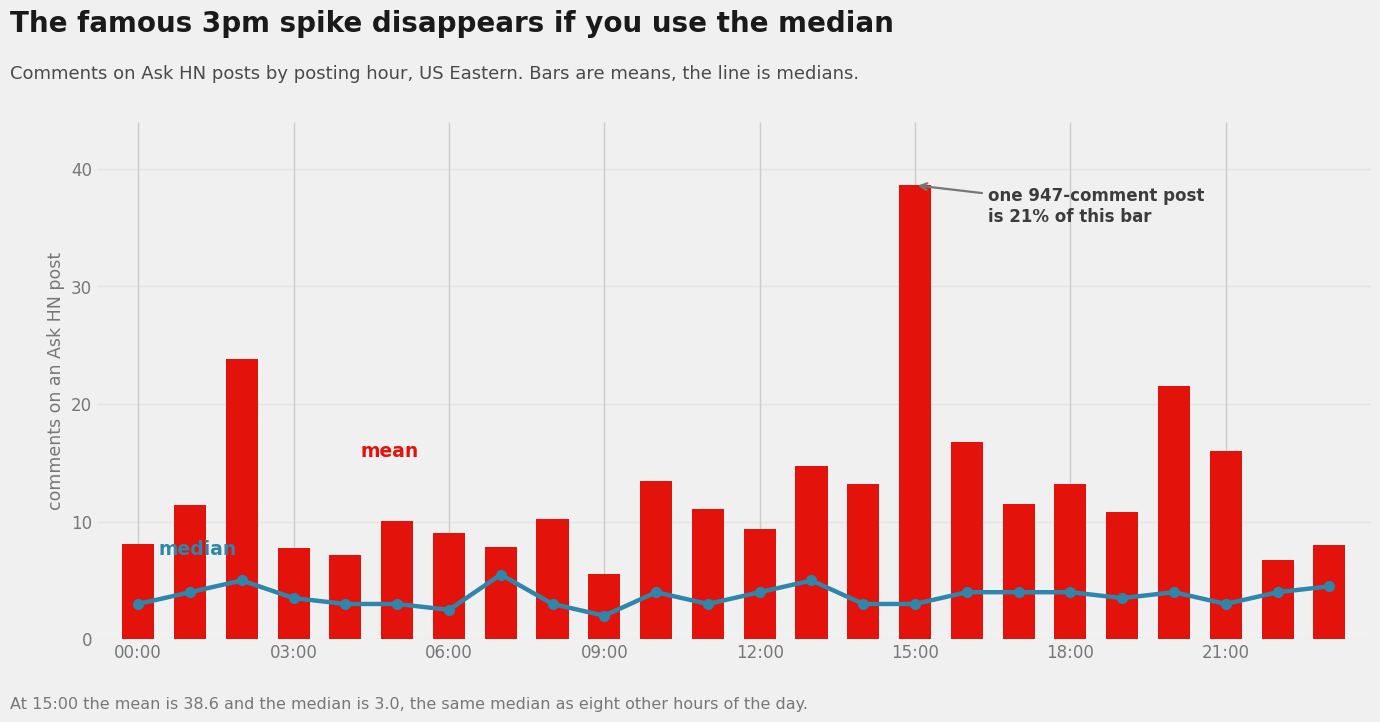

In [8]:
plt.style.use("fivethirtyeight")
C_MEAN = "#e3120b"
C_MED = "#2e86ab"
C_GREY = "#9a9a9a"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: mean against median by hour
hs = [r["hour"] for r in hour_rows]
means = [r["mean"] for r in hour_rows]
medians = [r["median"] for r in hour_rows]

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.bar(hs, means, color=C_MEAN, width=0.62, zorder=3)
ax.plot(hs, medians, color=C_MED, linewidth=3.2, marker="o", markersize=7, zorder=4)

ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels(["%02d:00" % h for h in range(0, 24, 3)], fontsize=12)
ax.set_xlim(-0.8, 23.8)
ax.set_ylim(0, 44)
ax.set_yticks([0, 10, 20, 30, 40])
ax.set_ylabel("comments on an Ask HN post", fontsize=12.5, color="#777777")
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="y")
for s in ax.spines.values():
    s.set_visible(False)

ax.annotate("one 947-comment post\nis 21% of this bar", xy=(15, 38.6), xytext=(16.4, 35.5),
            fontsize=12, color="#3c3c3c", weight="bold",
            arrowprops=dict(arrowstyle="->", color="#777777", linewidth=1.6))
ax.text(0.4, 7.2, "median", color=C_MED, fontsize=13.5, weight="bold")
ax.text(4.3, 15.5, "mean", color=C_MEAN, fontsize=13.5, weight="bold")

fig.subplots_adjust(left=0.075, right=0.985, top=0.805, bottom=0.115)
fig.text(0.013, 0.925, "The famous 3pm spike disappears if you use the median",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Comments on Ask HN posts by posting hour, US Eastern. Bars are means, the line is medians.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022,
         "At 15:00 the mean is 38.6 and the median is 3.0, the same median as eight other hours of the day.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds

all charts within bounds: True


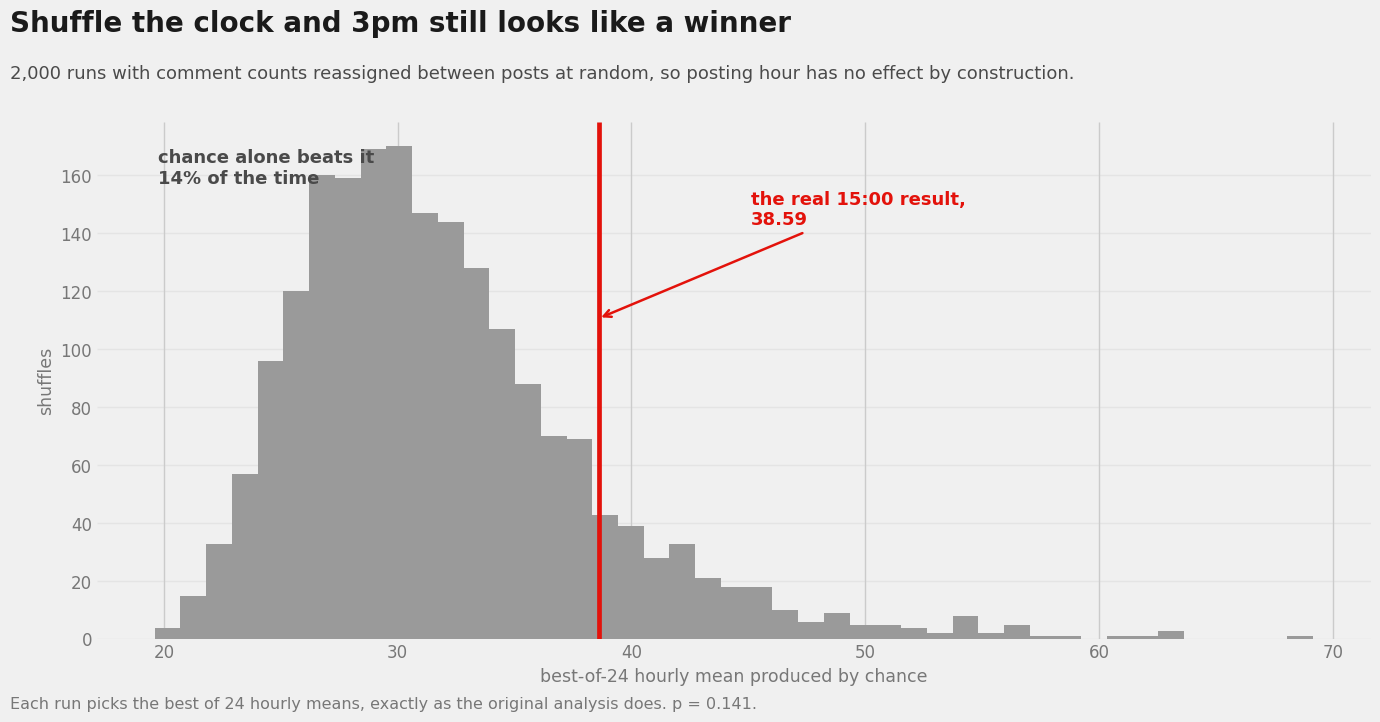

In [9]:
# Chart 2: the null distribution
fig, ax = plt.subplots(figsize=(14, 7.5))
ax.hist(shuffled_bests, bins=45, color=C_GREY, zorder=3)
ax.axvline(observed, color=C_MEAN, linewidth=3.4, zorder=5)

ax.set_xlabel("best-of-24 hourly mean produced by chance", fontsize=12.5, color="#777777")
ax.set_ylabel("shuffles", fontsize=12.5, color="#777777")
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="y")
for s in ax.spines.values():
    s.set_visible(False)

ymax = ax.get_ylim()[1]
ax.annotate("the real 15:00 result,\n38.59", xy=(observed, ymax * 0.62),
            xytext=(observed + 6.5, ymax * 0.80), fontsize=13, weight="bold", color=C_MEAN,
            arrowprops=dict(arrowstyle="->", color=C_MEAN, linewidth=1.8))
ax.text(shuffled_bests[int(0.5 * N_SHUFFLES)] - 11, ymax * 0.88,
        "chance alone beats it\n14% of the time", fontsize=13, weight="bold", color="#4a4a4a")

fig.subplots_adjust(left=0.075, right=0.985, top=0.805, bottom=0.115)
fig.text(0.013, 0.925, "Shuffle the clock and 3pm still looks like a winner",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "2,000 runs with comment counts reassigned between posts at random, so posting hour has no effect by construction.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022,
         "Each run picks the best of 24 hourly means, exactly as the original analysis does. p = 0.141.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
print()
print("all charts within bounds:", bool(ok1 and ok2))
plt.show()

## 8. Conclusions

### Claim one survives, at one comment

| Group | n | Median comments | Median points |
|---|---|---|---|
| Ask HN | 1,744 | **4** | 4 |
| Show HN | 1,162 | 3 | **6** |
| Everything else | 17,194 | 3 | **11** |

Ask HN posts do get more comments than Show HN posts, at p = 0.0032 by permutation test. The effect is **one comment at the median**.

**On points the ranking inverts.** Show HN takes 6 against Ask HN's 4, and ordinary link posts beat both at 11. The formats are not better and worse, they attract different responses: asking a question gets replies, showing work gets upvotes, posting a good link gets considerably more upvotes than either.

### Claim two does not survive

| Statistic | Best hour | Value |
|---|---|---|
| Mean | 15:00 | 38.59 |
| Median | 07:00 | 5.5 (n=34) |

By median, **15:00 scores 3.0, tying it with eight other hours of the day.** Its mean is inflated by a single 947-comment post supplying 21.2% of the hour's total. At 02:00, second by mean, one post supplies 62.9%.

The permutation test settles it. Shuffling comment counts between posts, so posting hour has no effect at all, and rerunning the full procedure including the pick-the-best step: **the chance best-hour mean reaches 38.59 or higher in 12.7% of 2,000 runs**, with a median of 30.8 and a 95th percentile of 43.8.

**p = 0.127. There is no evidence here that posting hour matters.**

Removing one post from the 116 at 15:00 drops that hour by 20%.

### The dataset cannot answer the question it is set

**The minimum comment count is 1 and the minimum point count is 1.** Not one of 20,100 posts received zero of either. The full Kaggle dump holds roughly 300,000 posts; this file has 20,100, filtered to submissions that got traction.

Every "what makes a post succeed?" question is therefore being asked of a sample with the failures removed. The answerable version is conditional: given that a post already got at least one comment and one point, what else is true of it? No analysis downstream recovers the missing posts.

### Why means were the wrong tool throughout

Comments have a mean of 24.80 and a median of 3.0, a ratio of 8.3. The top 1% of posts hold 15.5% of all comments. On a distribution shaped like that, a group mean is a statement about which viral posts happened to land in that group.

This shows up in the headline too: by mean, ordinary link posts get 26.87 comments against Ask HN's 14.04, reversing the project's first conclusion outright. By median they are 3 and 4.

### The practical answer

**Post whenever you like.** Nothing here supports a best hour. If you want comments, ask a question; if you want upvotes, post a good link. Both effects are small, and whatever actually determines how a post does is not in this file.

### What I would not claim

- **p = 0.127 is not proof that posting time is irrelevant.** It is a failure to detect an effect in a filtered sample of 1,744 Ask HN posts, which is a weak test. A real effect could exist and be invisible here.
- **Timestamps are US/Eastern** and the analysis treats the clock as the poster's, which holds only for US posters.
- **One year to September 2016,** on a site whose traffic and moderation have changed since.
- **Title prefix matching is crude.** "Ask HN:" is caught; a question phrased without the prefix counts as "other".
- **The permutation test holds hours fixed and shuffles outcomes,** so it tests whether hour predicts comments. It does not test whether different kinds of post are written at different hours, which is a different and probably more interesting question.

---

*Dataset: Hacker News posts, roughly twelve months to September 2016, from the Dataquest sample of the Kaggle dump.*